# تحليل فجوة الكيانات غير الربحية مقارنة بعدد السكان على مستوى المحافظات

**السؤال البحثي:** أي المحافظات فيها كيانات غير ربحية أقل من المتوقع مقارنة بعدد سكانها، وأين يُنصح الجهات المانحة بتوجيه الاهتمام أولًا؟

**صاحب القرار:** الجهات المانحة (مثل منصة مانح) أو المركز الوطني لتنمية القطاع غير الربحي.
**القرار المطلوب:** أي المحافظات تكون أولوية لتوجيه المنح ودراسة الاحتياج فيها.

---
## الجزء الأول: تنظيف البيانات

المدخلات في `data_raw/` لا تُعدَّل أبدًا؛ كل المخرجات تُكتب في `data_clean/`.
الدفتر يعمل من الأعلى للأسفل بدون أي تعديل يدوي، وكل المسارات نسبية لمجلد المشروع.

In [1]:
import re
from pathlib import Path

import pandas as pd
from IPython.display import display

RAW = Path('data_raw')
CLEAN = Path('data_clean')
CLEAN.mkdir(exist_ok=True)

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 200)

# Tables with Arabic text are shown with display() (HTML), because print() lays them out right-to-left
# and the columns appear in reverse order

# Every cleaning decision is appended here, printed at the end and saved to data_clean/cleaning_log.csv (copied into README)
cleaning_log = []

def log(step, issue, rows, decision):
    cleaning_log.append({'step': step, 'issue': issue, 'rows_affected': rows, 'decision': decision})

### 1. قراءة ملفات الكيانات (13 منطقة)

المصدر: منصة البيانات المفتوحة الوطنية (open.data.gov.sa)، الناشر: المركز الوطني لتنمية القطاع غير الربحي.

مشاكل القراءة:
- **الترميز:** ملفات تبوك ونجران وعسير بترميز Windows-1256 والباقي UTF-8 → نجرّب `utf-8-sig` أولًا ثم `cp1256`.
- **الصف الأول فارغ** (`,,,,,,,`) → `header=1`.
- **مسافة زائدة في اسم العمود** `"الرقم الوطني الموحد "` → نحذف المسافات من أسماء كل الأعمدة.
- **صفوف فارغة بالكامل** في نهاية كثير من الملفات → تُحذف.
- عمود المنطقة يُضاف من اسم الملف.

In [2]:
REGION_FILES = {
    'riyadh': 'الرياض',
    'makkah': 'مكة المكرمة',
    'madinah': 'المدينة المنورة',
    'eastern': 'المنطقة الشرقية',
    'qassim': 'القصيم',
    'asir': 'عسير',
    'tabuk': 'تبوك',
    'hail': 'حائل',
    'northern_borders': 'الحدود الشمالية',
    'jazan': 'جازان',
    'najran': 'نجران',
    'baha': 'الباحة',
    'jouf': 'الجوف',
}

frames = []
read_report = []
for file_key, region in REGION_FILES.items():
    path = RAW / f'{file_key}.csv'
    try:
        df_region = pd.read_csv(path, header=1, dtype=str, encoding='utf-8-sig')
        encoding = 'utf-8-sig'
    except UnicodeDecodeError:
        df_region = pd.read_csv(path, header=1, dtype=str, encoding='cp1256')
        encoding = 'cp1256'

    df_region.columns = df_region.columns.str.strip()
    rows_read = len(df_region)
    df_region = df_region.dropna(how='all')
    df_region['region_file'] = file_key
    df_region['region'] = region

    read_report.append({'file': path.name, 'encoding': encoding, 'columns': df_region.shape[1] - 2,
                        'rows_read': rows_read, 'empty_rows_dropped': rows_read - len(df_region),
                        'entities': len(df_region)})
    frames.append(df_region)

read_report = pd.DataFrame(read_report)
read_report

,file,encoding,columns,rows_read,empty_rows_dropped,entities
0,riyadh.csv,utf-8-sig,8,1683,0,1683
1,makkah.csv,utf-8-sig,8,1365,0,1365
2,madinah.csv,utf-8-sig,8,721,337,384
3,eastern.csv,utf-8-sig,8,712,188,524
4,qassim.csv,utf-8-sig,8,712,150,562
5,asir.csv,cp1256,8,693,157,536
6,tabuk.csv,cp1256,8,706,563,143
7,hail.csv,utf-8-sig,8,701,336,365
8,northern_borders.csv,utf-8-sig,8,133,0,133
9,jazan.csv,utf-8-sig,8,676,371,305


In [3]:
print('Total rows read      :', read_report['rows_read'].sum())
print('Empty rows dropped   :', read_report['empty_rows_dropped'].sum())
print('Entities kept        :', read_report['entities'].sum())

cp1256_files = read_report.loc[read_report['encoding'] == 'cp1256', 'file'].tolist()
log('1 Reading', 'ملفات بترميز Windows-1256: ' + '، '.join(cp1256_files),
    int(read_report.loc[read_report['encoding'] == 'cp1256', 'entities'].sum()),
    'القراءة بـ utf-8-sig ثم cp1256 عند الفشل')
log('1 Reading', 'الصف الأول فارغ في كل الملفات', 13, 'القراءة من الصف الثاني (header=1)')
log('1 Reading', 'مسافة زائدة في اسم العمود "الرقم الوطني الموحد "', 13, 'حذف المسافات من أسماء كل الأعمدة')
log('1 Reading', 'صفوف فارغة بالكامل في نهاية الملفات', int(read_report['empty_rows_dropped'].sum()), 'حُذفت')

Total rows read      : 9088
Empty rows dropped   : 2685
Entities kept        : 6403


### 2. توحيد الأعمدة ومعالجة ملف الجوف

ملف الجوف مختلف: **7 أعمدة فقط بدون "الرقم الوطني الموحد"**. نضيف العمود فارغًا لتوحيد الشكل،
وننشئ مفتاحًا للكيان `entity_key` = الرقم الوطني الموحد، أو اسم الكيان إذا لم يوجد رقم (الجوف).
ثم نعيد تسمية الأعمدة لأسماء إنجليزية قصيرة لتسهيل الكود.

In [4]:
for df_region in frames:
    if 'الرقم الوطني الموحد' not in df_region.columns:
        print('Missing ID column in:', df_region['region_file'].iloc[0], '-> added as empty')
        df_region['الرقم الوطني الموحد'] = pd.NA

npo = pd.concat(frames, ignore_index=True)

npo = npo.rename(columns={
    'الرقم الوطني الموحد': 'entity_id',
    'اسم الكيان': 'entity_name',
    'المدينة': 'city_raw',
    'التصنيف النوعي': 'category_raw',
    'التصنيف الفرعي الاول': 'subcategory_1',
    'التصنيف الفرعي الثاني': 'subcategory_2',
    'نوع الكيان': 'entity_type',
    'جهة الإشراف': 'supervisor',
})
npo = npo[['region_file', 'region', 'entity_id', 'entity_name', 'city_raw', 'category_raw',
           'subcategory_1', 'subcategory_2', 'entity_type', 'supervisor']]

print('Rows after concat:', len(npo))
print('Entities without ID:', npo['entity_id'].isna().sum(),
      npo.loc[npo['entity_id'].isna(), 'region_file'].value_counts().to_dict())

log('2 Columns', 'ملف الجوف 7 أعمدة بدون الرقم الوطني الموحد', int(npo['entity_id'].isna().sum()),
    'أضيف عمود الرقم فارغًا، واستُخدم اسم الكيان مفتاحًا لكيانات الجوف')

Missing ID column in: jouf -> added as empty
Rows after concat: 6403
Entities without ID: 62 {'jouf': 62}


### 3. توحيد النصوص

في كل الأعمدة النصية:
- حذف الأحرف غير المرئية (علامات الاتجاه U+200E و U+200F و U+202A–U+202E).
- حذف التطويل "ـ" (مثال: "أبـها" → "أبها").
- استبدال المسافات المتعددة بمسافة واحدة (مثال: "مدينة    عرعر") وحذف المسافات من الأطراف.

In [5]:
INVISIBLE = r'[\u200e\u200f\u202a-\u202e\ufeff]'
TEXT_COLS = ['entity_id', 'entity_name', 'city_raw', 'category_raw', 'subcategory_1',
             'subcategory_2', 'entity_type', 'supervisor']

before = npo[TEXT_COLS].copy()
for col in TEXT_COLS:
    npo[col] = (npo[col]
                .str.replace(INVISIBLE, '', regex=True)
                .str.replace('ـ', '', regex=False)
                .str.replace(r'\s+', ' ', regex=True)
                .str.strip())

changed = (before.fillna('') != npo[TEXT_COLS].fillna('')).sum()
print('Values changed per column:')
print(changed)

npo['entity_key'] = npo['entity_id'].fillna(npo['entity_name'])

log('3 Text', 'أحرف غير مرئية وتطويل ومسافات متكررة', int(changed.sum()),
    'حُذفت أو وُحّدت في كل الأعمدة النصية')

Values changed per column:
entity_id           0
entity_name        87
city_raw         2717
category_raw        0
subcategory_1       0
subcategory_2       0
entity_type         0
supervisor         21
dtype: int64


### 4. استخراج المحافظة من عمود "المدينة"

المحافظة مكتوبة ببادئة: "محافظة " أو "مدينة " (لعاصمة المنطقة) أو "مركز ". نحذف البادئة.
ملف الجوف بدون بادئة أصلًا.

In [6]:
prefix = npo['city_raw'].str.extract(r'^(محافظة|مدينة|مركز) ')[0]
print('Prefixes found:')
display(prefix.value_counts(dropna=False).to_frame('rows'))

npo['governorate'] = npo['city_raw'].str.replace(r'^(محافظة|مدينة|مركز) ', '', regex=True)
print('Unique governorate values:', npo['governorate'].nunique())

log('4 Governorate prefix', 'بادئة "محافظة/مدينة/مركز" في عمود المدينة', int(prefix.notna().sum()),
    'حُذفت البادئة وأنشئ عمود governorate')

Prefixes found:


,rows
0,
محافظة,3409
مدينة,2822
NaN,171
مركز,1


Unique governorate values: 163


### 5. التصنيف النوعي

- **التصنيف المختصر** = النص قبل "(" بعد حذف ":" . هذا يوحّد المجموعة الخامسة (البيئة) التي تظهر بوصفين مختلفين.
- **HMS_Check** (صفّان في المدينة المنورة): تصنيفهما الفرعي "التنمية الاجتماعية" → المجموعة السادسة التنمية و الإسكان.
- **منشأة بأمر ملكي**: تبقى فئة مستقلة مع عمود علامة `is_royal_decree`.
- **جهة الإشراف المفقودة**: تبقى ويُبلّغ عنها.

In [7]:
npo['category'] = (npo['category_raw'].str.split('(').str[0]
                   .str.replace(':', '', regex=False)
                   .str.replace(r'\s+', ' ', regex=True)
                   .str.strip())

print('Group 5 raw descriptions -> one short category:')
display(npo.loc[npo['category'].str.contains('الخامسة'), 'category_raw'].value_counts().to_frame('rows'))

hms = npo['category'] == 'HMS_Check'
print('HMS_Check rows:')
display(npo.loc[hms, ['region', 'entity_name', 'subcategory_1', 'subcategory_2']])
npo.loc[hms, 'category'] = 'المجموعة السادسة التنمية و الإسكان'

npo['is_royal_decree'] = npo['category'] == 'منشأة بأمر ملكي'
print('Royal decree entities per region:', npo.loc[npo['is_royal_decree'], 'region_file'].value_counts().to_dict())
print('Their supervisor values:', npo.loc[npo['is_royal_decree'], 'supervisor'].value_counts(dropna=False).to_dict(), '\n')

missing_supervisor = npo['supervisor'].isna()
print('Missing supervisor:')
display(npo.loc[missing_supervisor, ['region', 'entity_name', 'category']])

display(npo['category'].value_counts().to_frame('entities'))

log('5 Categories', 'نص التصنيف طويل، والمجموعة الخامسة (البيئة) بوصفين أحدهما خاطئ', len(npo),
    'التصنيف المختصر = النص قبل "(" بدون ":"')
log('5 Categories', 'تصنيف "HMS_Check" (قيمة اختبار، تصنيفه الفرعي التنمية الاجتماعية)', int(hms.sum()),
    'نُقل إلى المجموعة السادسة التنمية و الإسكان')
log('5 Categories', 'تصنيف "منشأة بأمر ملكي" (جهة الإشراف "-" غالبًا)', int(npo['is_royal_decree'].sum()),
    'بقي فئة مستقلة مع عمود is_royal_decree')
log('5 Categories', 'جهة إشراف مفقودة', int(missing_supervisor.sum()), 'أُبقي ووُثّق')

Group 5 raw descriptions -> one short category:


,rows
category_raw,
المجموعة الخامسة البيئة (المنظمات التي تقدم خدمات إنسانية واجتماعية للمجتمع لفئات مستهدفة),234
المجموعة الخامسة البيئة (المنظمات التي تعزز وتوفر الخدمات التي تٌعنى بالمحافظة على البيئة ومكافحة التلوث والوقاية والتثقيف البيئي والصحي، وحماية الحيوان),75


HMS_Check rows:


,region,entity_name,subcategory_1,subcategory_2
3050,المدينة المنورة,جمعية البر والخدمات الاجتماعية بمركز صفينة,التنمية الاجتماعية والاقتصادية والمجتمعية,خدمات التنمية الاجتماعية
3051,المدينة المنورة,جمعية البر والخدمات الاجتماعية بمركز ابو ضباع,التنمية الاجتماعية والاقتصادية والمجتمعية,خدمات التنمية الاجتماعية


Royal decree entities per region: {'riyadh': 19, 'makkah': 2, 'tabuk': 1}
Their supervisor values: {'-': 21, 'وزارة البيئة والمياه والزراعة': 1} 

Missing supervisor:


,region,entity_name,category
5194,تبوك,أفق السينما,المجموعة الأولى الثقافة والترفيه


,entities
category,
المجموعة الرابعة الخدمات الاجتماعية,1607
المجموعة السادسة التنمية و الإسكان,1297
المجموعة التاسعة منظمات الدعوة والإرشاد والتعليم الديني وخدمة ضيوف الرحمن,1145
المجموعة الثالثة الصحة,481
المجموعة الثامنة منظمات دعم العمل الخيري,454
المجموعة الثانية التعليم والأبحاث,400
المجموعة الأولى الثقافة والترفيه,361
المجموعة الخامسة البيئة,309
المجموعة العاشرة الروابط المهنية,222


### 6. فحص التكرار

بعد دمج الملفات نفحص تكرار الرقم الوطني الموحد وتكرار اسم الكيان عبر كل الملفات.

In [8]:
dup_ids = npo['entity_id'].dropna().duplicated().sum()
dup_names = npo['entity_name'].duplicated().sum()
print('Duplicate entity IDs  :', dup_ids)
print('Duplicate entity names:', dup_names)
if dup_names:
    display(npo[npo['entity_name'].duplicated(keep=False)].sort_values('entity_name')
          [['region', 'entity_id', 'entity_name', 'city_raw']])

log('6 Duplicates', 'تكرار الرقم الوطني أو الاسم عبر الملفات الـ13', int(dup_ids + dup_names),
    'لا يوجد تكرار' if dup_ids + dup_names == 0 else 'معروض أعلاه')

Duplicate entity IDs  : 0
Duplicate entity names: 0


### 7. بيانات السكان (تعداد 2022)

`data_raw/population_citypopulation_raw.csv` منسوخ يدويًا من citypopulation.de (الأرقام من تعداد الهيئة العامة للإحصاء 2022).
الأعمدة: name_en, status, name_ar, population (نص بفواصل). الصفوف: منطقة ثم محافظاتها.

- نُبقي صفوف المحافظات فقط (150)، ونعطي كل محافظة منطقتها من صف المنطقة الذي فوقها (ffill).
- نحوّل السكان لأرقام صحيحة.
- المحافظات المستحدثة مكتوب عندها في name_en "[← المحافظة الأم]"؛ نحفظها في عمود `split_from`.
- تصحيح أخطاء إملائية في ملف السكان نفسه.

In [9]:
pop_raw = pd.read_csv(RAW / 'population_citypopulation_raw.csv', dtype=str, encoding='utf-8-sig')
print('Rows read:', len(pop_raw), pop_raw['status'].value_counts().to_dict())

pop_raw['name_ar'] = (pop_raw['name_ar']
                      .str.replace(INVISIBLE, '', regex=True)
                      .str.replace(r'\s+', ' ', regex=True)
                      .str.strip())
pop_raw['population'] = pop_raw['population'].str.replace(',', '', regex=False).astype(int)
pop_raw['region'] = pop_raw['name_ar'].where(pop_raw['status'] == 'Region').ffill()

site_region_rows = pop_raw[pop_raw['status'] == 'Region'].set_index('region')['population']

pop = pop_raw[pop_raw['status'] == 'Governorate'].copy()
pop['split_from'] = pop['name_en'].str.extract(r'\[← (.+)\]')[0]
pop = pop.rename(columns={'name_ar': 'governorate'})[['region', 'governorate', 'name_en', 'split_from', 'population']]

POP_NAME_FIX = {
    'العويقيله': 'العويقيلة',
    'ضريه': 'ضرية',
    'يدمه': 'يدمة',
}
pop['governorate'] = pop['governorate'].replace(POP_NAME_FIX)

print('Governorate rows:', len(pop))
print('Newly split governorates:', pop['split_from'].notna().sum())
assert not pop.duplicated(['governorate']).any(), 'Governorate names must be unique across regions'
assert set(pop['region']) == set(REGION_FILES.values()), 'Region names must match the nonprofit files'

log('7 Population', 'صفوف المناطق والمحافظات مختلطة في ملف واحد', len(pop_raw), 'أُبقيت 150 محافظة، والمنطقة من الصف الذي فوقها (ffill)')
log('7 Population', 'أخطاء إملائية في ملف السكان: ' + '، '.join(f'{k} ← {v}' for k, v in POP_NAME_FIX.items()),
    len(POP_NAME_FIX), 'صُححت في ملف السكان')

Rows read: 163 {'Governorate': 150, 'Region': 13}
Governorate rows: 150
Newly split governorates: 33


#### التحقق من مجاميع السكان

نجمع سكان المحافظات لكل منطقة ونقارنها بالأرقام الرسمية لتعداد 2022 (الهيئة العامة للإحصاء).
كل المناطق تتطابق، **ما عدا صفّي المنطقة لمكة المكرمة والمدينة المنورة في الموقع**: مبدّلان بفرق 251,469.
مجاميع المحافظات نفسها تطابق الأرقام الرسمية، لذلك نتجاهل صفوف المناطق في الموقع ونحسب إجمالي المنطقة من مجموع محافظاتها.

In [10]:
OFFICIAL_2022 = {  # GASTAT Census 2022, region totals
    'الرياض': 8_591_748, 'مكة المكرمة': 8_021_463, 'المنطقة الشرقية': 5_125_254,
    'المدينة المنورة': 2_137_983, 'عسير': 2_024_285, 'جازان': 1_404_997, 'القصيم': 1_336_179,
    'تبوك': 886_036, 'حائل': 746_406, 'الجوف': 595_822, 'نجران': 592_300,
    'الحدود الشمالية': 373_577, 'الباحة': 339_174,
}

validation = pd.DataFrame({
    'governorate_sum': pop.groupby('region')['population'].sum(),
    'site_region_row': site_region_rows,
    'official_2022': pd.Series(OFFICIAL_2022),
})
validation['sum_minus_official'] = validation['governorate_sum'] - validation['official_2022']
validation['site_row_minus_official'] = validation['site_region_row'] - validation['official_2022']
validation = validation.sort_values('official_2022', ascending=False)
display(validation)
print('\nKingdom total (governorate sum):', f"{validation['governorate_sum'].sum():,}")

assert (validation['sum_minus_official'] == 0).all(), 'Governorate sums must match official totals'

swapped = validation.index[validation['site_row_minus_official'] != 0].tolist()
log('7 Population', 'صفا المنطقة في الموقع خاطئان: ' + ' و'.join(swapped) + ' (مبدّلان بفرق 251,469)', len(swapped),
    'تجاهلنا صفوف المناطق؛ إجمالي المنطقة = مجموع محافظاتها (يطابق الرسمي)')

,governorate_sum,site_region_row,official_2022,sum_minus_official,site_row_minus_official
الرياض,8591748,8591748,8591748,0,0
مكة المكرمة,8021463,7769994,8021463,0,-251469
المنطقة الشرقية,5125254,5125254,5125254,0,0
المدينة المنورة,2137983,2389452,2137983,0,251469
عسير,2024285,2024285,2024285,0,0
جازان,1404997,1404997,1404997,0,0
القصيم,1336179,1336179,1336179,0,0
تبوك,886036,886036,886036,0,0
حائل,746406,746406,746406,0,0
الجوف,595822,595822,595822,0,0



Kingdom total (governorate sum): 32,175,224


### 8. توحيد أسماء المحافظات بين الملفين

قاموس واحد صريح يحوّل كتابة ملفات الكيانات إلى الكتابة الصحيحة الموجودة في ملف السكان.

In [11]:
NPO_NAME_FIX = {
    # riyadh
    'ضرماء': 'ضرما',
    # makkah
    'جده': 'جدة', 'القنفذه': 'القنفذة', 'بحره': 'بحرة', 'رنيه': 'رنية',
    # madinah
    'ينبع': 'ينبع البحر', 'المهد': 'مهد الذهب',
    # eastern
    'الإحساء': 'الأحساء', 'أبقيق': 'بقيق',
    # asir
    'بلقرن': 'بالقرن',
    # baha
    'بالجرشي': 'بلجرشي', 'قلوه': 'قلوة', 'غامد الزناد': 'فرعة غامد الزناد',
    # jazan
    'جازان': 'جيزان', 'صبياء': 'صبيا', 'جزر فرسان': 'فرسان',
}

renamed = npo['governorate'].isin(NPO_NAME_FIX.keys())
print('Rows renamed:', renamed.sum())
display(npo.loc[renamed, 'governorate'].value_counts().to_frame('rows'))
npo['governorate'] = npo['governorate'].replace(NPO_NAME_FIX)

log('8 Name harmonization', 'كتابة مختلفة عن ملف السكان: ' + '، '.join(f'{k} ← {v}' for k, v in NPO_NAME_FIX.items()),
    int(renamed.sum()), 'وُحّدت على كتابة ملف السكان')

Rows renamed:

 991


,rows
governorate,
جده,416
الإحساء,134
القنفذه,107
جازان,104
ينبع,44
رنيه,36
صبياء,35
بلقرن,23
بالجرشي,21


### 9. حالات المحافظة التي تحتاج قرارًا

لا نخمّن بصمت. كل حالة غير واضحة لها قرار صريح في القواميس التالية (مفتاحها الرقم الوطني الموحد، أو الاسم في الجوف)،
وكل صف لم يُحسم يبقى في ملف الكيانات مع علامة `gov_status = unresolved` وسبب في `gov_flag`، ولا يدخل في عدّ المحافظات.

- **"أخرى"** كمحافظة (109 صفًا).
- **مراكز/قرى بدل محافظات** (مركز أبو ضباع في المدينة، وعدة مراكز في الجوف، و"الجوف" اسم المنطقة).
- **محافظات مستحدثة غير موجودة في تعداد 2022**: الفرشة (عسير)، أبانات (القصيم)، البيضاء (الشرقية). سكانها محسوبون داخل محافظة أم.
- **محافظة تتبع منطقة أخرى غير منطقة الملف** → تُنقل المنطقة حسب منطقة المحافظة الحقيقية في ملف السكان، ما عدا الحالات المعلّقة للمراجعة.

In [12]:
# Manual decisions: entity_key -> governorate (as spelled in the population file), or None to exclude
MANUAL_GOVERNORATE = {
    # jazan file, city "مدينة الرياض", but name says "بمحافظة فيفاء" -> Fifa (Jazan), not Riyadh
    '7051820046': 'فيفا',
    # jouf file, city "الرياض"; الحديثة is a centre of Al-Qurayyat governorate, not Riyadh city
    'جمعية التنمية الأهلية بالحديثة': 'القريات',
    # jouf file, centre العيساوية; the name itself says "بمحافظة القريات"
    'جمعية البر بمركز بالعيساوية بمحافظة القريات': 'القريات',
    # governorate = "أخرى", place named in the entity name
    '7001394019': 'خيبر',         # جمعية البر الخيرية بخيبر
    '7026222997': 'الزلفي',       # جمعية التنمية الأهلية بالزلفي
    '7001518674': 'النعيرية',     # ... توعية الجاليات في النعيرية
    '7009149258': 'الأحساء',      # جمعية التنمية الأهلية بالعيون (العيون in Al-Ahsa)
    '7001448146': 'رابغ',         # جمعية البر الأهلية بمستورة
    '7033706503': 'مكة المكرمة',  # جمعية التنمية الأهلية بالشرائع
    '7031126647': 'المجمعة',      # جمعية البر بحرمه
    '7001562334': 'بدر',          # ... بالواسطة
    '7001770606': 'بدر',          # ... بمركز الواسطة
    '7001775209': 'بدر',          # ... بالمسيجيد
    '8000001236': 'مهد الذهب',    # رعاية الايتام بحاذة
    '8000003881': 'رابغ',         # جمعية التنمية الأهلية بحجر
    '7001646863': 'الدوادمي',     # الجمعية الخيرية بمركز شبيرمة
    # centres written instead of governorates (affiliation checked on saudipedia.com lists of administrative centres)
    'خدمات الحجاج والمعتمرين بالجوف': 'دومة الجندل',    # مركز أبو عجرم
    'جمعية البر الخيرية بالأضارع': 'دومة الجندل',       # مركز الأضارع
    'جمعية التنمية الأهلية بالأضارع': 'دومة الجندل',
    'جمعية البر الخيرية بالناصفة': 'القريات',           # مركز الناصفة
    'جمعية التنمية الأهلية بالناصفة': 'القريات',
    'جمعية البر الخيرية بميقوع': 'طبرجل',               # مركز ميقوع
    'جمعية البر بمركز الوادي': 'القريات',               # city "غطي"; name says مركز الوادي (Al-Qurayyat)
    '7009426979': 'وادي الفرع',                         # مركز أبو ضباع (Madinah)
    # city in another region, name points to a centre in the file's own region (kept in original region)
    '7053343765': 'رفحاء',     # northern_borders, city "حفر الباطن", name "بروضة هباس" (مركز بن هباس)
    '7051820160': 'سميراء',    # hail, city "العلا", name "بكتيفة" (مركز كتيفة)
    '7053429218': 'المخواة',   # baha, city "جده", name "بناوان" (مركز ناوان)
}

# New governorates not in Census 2022: name -> parent governorate to merge into (approved by the team)
NEW_GOVERNORATE_PARENT = {
    'الفرشة': 'سراة عبيدة',   # asir
    'أبانات': 'الرس',         # qassim
    'البيضاء': 'الدمام',      # eastern
    'صوير': 'سكاكا',          # jouf (now a governorate; not in Census 2022)
}
NEW_GOVERNORATES = ['الفرشة', 'أبانات', 'البيضاء', 'صوير']

# Rows held for review (none left after the team's decisions)
PENDING_REVIEW = {
}

In [13]:
gov_region = pop.set_index('governorate')['region']
npo['region_original'] = npo['region']
npo['gov_status'] = 'ok'
npo['gov_flag'] = ''

# Every decision must point to an existing entity and a governorate in the population file
assert set(MANUAL_GOVERNORATE) <= set(npo['entity_key']), set(MANUAL_GOVERNORATE) - set(npo['entity_key'])
assert set(v for v in MANUAL_GOVERNORATE.values() if v) <= set(gov_region.index)
assert set(NEW_GOVERNORATE_PARENT.values()) <= set(gov_region.index)

# 9a. Manual decisions
manual = npo['entity_key'].isin(MANUAL_GOVERNORATE.keys())
npo.loc[manual, 'governorate'] = npo.loc[manual, 'entity_key'].map(MANUAL_GOVERNORATE)
npo.loc[manual, 'gov_status'] = 'manual'
npo.loc[manual, 'gov_flag'] = 'manual decision (MANUAL_GOVERNORATE)'
npo.loc[manual & npo['governorate'].isna(), 'gov_status'] = 'excluded'

# 9b. New governorates -> parent (or exclude) once decided
new_gov = npo['governorate'].isin(NEW_GOVERNORATE_PARENT.keys()) & ~manual
npo.loc[new_gov, 'gov_flag'] = 'new governorate merged into parent: ' + npo.loc[new_gov, 'governorate']
npo.loc[new_gov, 'governorate'] = npo.loc[new_gov, 'governorate'].map(NEW_GOVERNORATE_PARENT)
npo.loc[new_gov, 'gov_status'] = 'manual'
npo.loc[new_gov & npo['governorate'].isna(), 'gov_status'] = 'excluded'

# 9c. Held for review
pending = npo['entity_key'].isin(PENDING_REVIEW.keys()) & ~manual
npo.loc[pending, 'gov_status'] = 'unresolved'
if pending.any():
    npo.loc[pending, 'gov_flag'] = 'pending review: ' + npo.loc[pending, 'entity_key'].map(PENDING_REVIEW)

# 9d. Anything else not found in the population file
open_rows = npo['gov_status'].eq('ok')
not_found = open_rows & ~npo['governorate'].isin(gov_region.index)
npo.loc[not_found, 'gov_status'] = 'unresolved'
npo.loc[not_found & (npo['governorate'] == 'أخرى'), 'gov_flag'] = 'governorate = أخرى'
npo.loc[not_found & npo['governorate'].isin(NEW_GOVERNORATES), 'gov_flag'] = 'new governorate, not in Census 2022'
npo.loc[not_found & (npo['gov_flag'] == ''), 'gov_flag'] = 'centre/village or region name, not a governorate'

# 9e. Governorate belongs to another region -> reassign region
resolved = npo['gov_status'].isin(['ok', 'manual'])
real_region = npo['governorate'].map(gov_region)
moved = resolved & (real_region != npo['region'])
print('Region reassigned (governorate belongs to another region):')
display(npo.loc[moved, ['region_file', 'entity_key', 'entity_name', 'city_raw', 'governorate']].assign(new_region=real_region[moved]))
npo.loc[moved, 'region'] = real_region[moved]
npo.loc[moved, 'gov_flag'] = 'region reassigned from ' + npo.loc[moved, 'region_original']

print(npo['gov_status'].value_counts(), '\n')
print('Unresolved by reason and file:')
display(npo[npo['gov_status'] == 'unresolved'].groupby(['gov_flag', 'region_file']).size().to_frame('entities'))

Region reassigned (governorate belongs to another region):


,region_file,entity_key,entity_name,city_raw,governorate,new_region


gov_status
ok            6242
unresolved      97
manual          64
Name: count, dtype: int64 

Unresolved by reason and file:


entities
gov_flag                                         region_file          
centre/village or region name, not a governorate jouf                1
governorate = أخرى                               asir                1
                                                 eastern            15
                                                 hail                1
                                                 jazan               4
                                                 madinah             4
                                                 makkah             20
                                                 qassim              6
                                                 riyadh             44
                                                 tabuk               1

In [14]:
if moved.any():
    log('9 Governorate decisions', 'المحافظة تتبع منطقة غير منطقة الملف', int(moved.sum()),
        'نُقلت المنطقة حسب ملف السكان، والأصل في region_original')
if manual.any():
    log('9 Governorate decisions', 'محافظة غير واضحة (أخرى، مركز بدل محافظة، أو مدينة تخالف اسم الكيان)', int(manual.sum()),
        'قرار يدوي من الفريق بعد التحقق من اسم الكيان والمصادر (MANUAL_GOVERNORATE)')
if new_gov.any():
    log('9 Governorate decisions', 'محافظات مستحدثة غير موجودة في تعداد 2022: ' + '، '.join(NEW_GOVERNORATE_PARENT), int(new_gov.sum()),
        'دُمجت في المحافظة الأم: ' + '، '.join(f'{k} ← {v}' for k, v in NEW_GOVERNORATE_PARENT.items()))
if pending.any():
    log('9 Governorate decisions', 'حالات معلّقة للمراجعة', int(pending.sum()), 'بقيت معلّقة')
UNRESOLVED_AR = {
    'governorate = أخرى': 'المحافظة "أخرى" (جمعيات وطنية أو مهنية أو عائلية أو على مستوى منطقة)',
    'centre/village or region name, not a governorate': 'اسم المنطقة مكتوب بدل المحافظة',
    'new governorate, not in Census 2022': 'محافظة مستحدثة غير موجودة في تعداد 2022',
}
for reason, n in npo.loc[npo['gov_status'] == 'unresolved', 'gov_flag'].value_counts().items():
    if not reason.startswith('pending review'):
        log('9 Governorate decisions', UNRESOLVED_AR.get(reason, reason), int(n), 'بقيت معلّقة ولا تدخل في عدّ المحافظات (قيد يُذكر في التقرير)')

In [15]:
print('Rows still unresolved (full list, for decisions):')
npo.loc[npo['gov_status'] == 'unresolved',
        ['region_file', 'entity_key', 'entity_name', 'city_raw', 'gov_flag']].sort_values(['gov_flag', 'region_file'])

Rows still unresolved (full list, for decisions):


,region_file,entity_key,entity_name,city_raw,gov_flag
6343,jouf,الوفاء لرعاية المسنين بالجوف,الوفاء لرعاية المسنين بالجوف,الجوف,"centre/village or region name, not a governorate"
4689,asir,8000003297,مؤسسة حامد سعيد العلياني ووالديه,أخرى,governorate = أخرى
3458,eastern,8000004506,مؤسسة ماضي بن محمد الهاجري للتنمية الاجتماعية والأعمال الخيرية,أخرى,governorate = أخرى
3469,eastern,7020692658,مؤسسة عبدالرحمن بن صالح العطيشان وعائلتة,أخرى,governorate = أخرى
3470,eastern,7001648984,مؤسسة عبدالرحمن بن صالح الراجحي وعائلتة الخيرية,أخرى,governorate = أخرى
3473,eastern,8000004384,مؤسسة سعد بن إبراهيم عبدالله الوهيبي الخيرية,أخرى,governorate = أخرى
3476,eastern,7009447041,مؤسسة حسن بن حسين آل عبدالقادر,أخرى,governorate = أخرى
3478,eastern,7023461788,مؤسسة القنبر للخدمات الانسانية,أخرى,governorate = أخرى
3612,eastern,8000003154,جمعية مكافحة الاحتيال بالمنطقة الشرقية,أخرى,governorate = أخرى
3626,eastern,7021915942,جمعية فرسان الشرقية للبحث والإنقاذ,أخرى,governorate = أخرى


**الكيانات التي بقيت بدون محافظة:**
- **"أخرى" (96 كيانًا):** جمعيات وطنية أو مهنية أو مؤسسات عائلية أو كيانات تعمل على مستوى منطقة كاملة، فلا تُنسب لمحافظة واحدة.
  ويشمل ذلك جمعية سدير الثقافية (سدير إقليم وليس محافظة)، والسالمية والمحوى (بحثنا عن تبعيتهما الإدارية ولم نجد مصدرًا يؤكدها).
- **"الوفاء لرعاية المسنين بالجوف" (1):** مكتوب في خانة المدينة "الجوف" وهو اسم المنطقة.

هذه الكيانات (حوالي 1.5% من الإجمالي) تبقى في ملف الكيانات النظيف ولا تدخل في عدّ المحافظات، وتُذكر كقيد في التقرير.

### 10. الدمج مع السكان

نعدّ الكيانات لكل (منطقة، محافظة) من الصفوف المحسومة فقط، ثم دمج يساري على ملف السكان
حتى تبقى المحافظات التي ليس فيها أي كيان (عددها 0).
المحافظات المستحدثة التي عددها 0 قد تكون كياناتها مسجلة تحت المحافظة الأم؛ نضع لها ملاحظة.

In [16]:
resolved = npo['gov_status'].isin(['ok', 'manual'])
counts = npo[resolved].groupby(['region', 'governorate']).size().rename('npo_count').reset_index()

unmatched = counts.merge(pop[['region', 'governorate']], on=['region', 'governorate'], how='left', indicator=True)
unmatched = unmatched[unmatched['_merge'] == 'left_only']
print('Resolved governorates with no population match:', len(unmatched))
print(unmatched)
assert unmatched.empty

gov = pop.merge(counts, on=['region', 'governorate'], how='left')
gov['npo_count'] = gov['npo_count'].fillna(0).astype(int)
gov['note'] = ''
zero_split = (gov['npo_count'] == 0) & gov['split_from'].notna()
gov.loc[zero_split, 'note'] = 'new governorate with 0 entities; entities may be registered under parent'

print('\nGovernorates:', len(gov))
print('Governorates with 0 entities:', (gov['npo_count'] == 0).sum())
print(gov.loc[gov['npo_count'] == 0, ['region', 'governorate', 'split_from', 'population']])

print('\nEntity reconciliation:')
print('  counted in governorates:', gov['npo_count'].sum())
print('  unresolved            :', (npo['gov_status'] == 'unresolved').sum())
print('  excluded              :', (npo['gov_status'] == 'excluded').sum())
print('  total                 :', len(npo))
assert gov['npo_count'].sum() + (~resolved).sum() == len(npo)

log('10 Merge', 'محافظات بدون أي كيان', int((gov['npo_count'] == 0).sum()),
    'تبقى بعدد 0 (دمج يساري على ملف السكان)')

Resolved governorates with no population match: 0
Empty DataFrame
Columns: [region, governorate, npo_count, _merge]
Index: []

Governorates: 150
Governorates with 0 entities: 0
Empty DataFrame
Columns: [region, governorate, split_from, population]
Index: []

Entity reconciliation:
  counted in governorates: 6306
  unresolved            : 97
  excluded              : 0
  total                 : 6403


### 11. حفظ المخرجات وسجل التنظيف

In [17]:
npo_out = npo[['entity_key', 'entity_id', 'entity_name', 'region', 'region_original', 'region_file',
               'city_raw', 'governorate', 'gov_status', 'gov_flag', 'category', 'subcategory_1',
               'subcategory_2', 'entity_type', 'supervisor', 'is_royal_decree']]
npo_out.to_csv(CLEAN / 'npo_all_regions_clean.csv', index=False, encoding='utf-8-sig')
pop.to_csv(CLEAN / 'population_governorate_2022.csv', index=False, encoding='utf-8-sig')
gov[['region', 'governorate', 'npo_count', 'population', 'split_from', 'note']].to_csv(
    CLEAN / 'governorate_npo_population.csv', index=False, encoding='utf-8-sig')

for f in sorted(CLEAN.glob('*.csv')):
    print(f, len(pd.read_csv(f)), 'rows')

data_clean\cleaning_log.csv 21 rows
data_clean\governorate_npo_population.csv 150 rows
data_clean\npo_all_regions_clean.csv 6403 rows
data_clean\population_governorate_2022.csv 150 rows


In [18]:
cleaning_log = pd.DataFrame(cleaning_log)
cleaning_log.to_csv(CLEAN / 'cleaning_log.csv', index=False, encoding='utf-8-sig')
cleaning_log

,step,issue,rows_affected,decision
0,1 Reading,ملفات بترميز Windows-1256: asir.csv، tabuk.csv، najran.csv,818,القراءة بـ utf-8-sig ثم cp1256 عند الفشل
1,1 Reading,الصف الأول فارغ في كل الملفات,13,القراءة من الصف الثاني (header=1)
2,1 Reading,"مسافة زائدة في اسم العمود ""الرقم الوطني الموحد """,13,حذف المسافات من أسماء كل الأعمدة
3,1 Reading,صفوف فارغة بالكامل في نهاية الملفات,2685,حُذفت
4,2 Columns,ملف الجوف 7 أعمدة بدون الرقم الوطني الموحد,62,أضيف عمود الرقم فارغًا، واستُخدم اسم الكيان مفتاحًا لكيانات الجوف
5,3 Text,أحرف غير مرئية وتطويل ومسافات متكررة,2825,حُذفت أو وُحّدت في كل الأعمدة النصية
6,4 Governorate prefix,"بادئة ""محافظة/مدينة/مركز"" في عمود المدينة",6232,حُذفت البادئة وأنشئ عمود governorate
7,5 Categories,نص التصنيف طويل، والمجموعة الخامسة (البيئة) بوصفين أحدهما خاطئ,6403,"التصنيف المختصر = النص قبل ""("" بدون "":"""
8,5 Categories,"تصنيف ""HMS_Check"" (قيمة اختبار، تصنيفه الفرعي التنمية الاجتماعية)",2,نُقل إلى المجموعة السادسة التنمية و الإسكان
9,5 Categories,"تصنيف ""منشأة بأمر ملكي"" (جهة الإشراف ""-"" غالبًا)",22,بقي فئة مستقلة مع عمود is_royal_decree


---
## الجزء الثاني: التحليل

**الفكرة باختصار:** لكي نقول إن محافظة فيها جمعيات "أقل من المتوقع"، نحتاج أولًا أن نعرف **كم المتوقع** لمحافظة بحجمها.

1. نتحقق: هل تكفي نسبة ثابتة (معدل المملكة لكل 100 ألف نسمة) لحساب المتوقع؟
2. نبني **نموذج تعلّم آلة (انحدار خطي)** يمثّل "الطبيعي" يقارن كل محافظة بالمحافظات التي في حجمها.
3. نحدد المحافظات التي تقع **تحت النطاق الطبيعي بوضوح**، ونرتّبها كأولويات للمانحين.

المدخل: `data_clean/governorate_npo_population.csv` (150 محافظة).

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import arabic_reshaper
from bidi.algorithm import get_display
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

OUTPUTS = Path('outputs')
FIGURES = OUTPUTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

def ar(text):
    # matplotlib does not join Arabic letters or order them right-to-left by itself
    return get_display(arabic_reshaper.reshape(text))

INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#b9b8b2'
plt.rcParams.update({
    'font.family': ['Tahoma', 'DejaVu Sans'],
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': INK_2, 'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
})

gov = pd.read_csv(CLEAN / 'governorate_npo_population.csv')
gov['per_100k'] = gov['npo_count'] / gov['population'] * 100_000
print('Governorates:', len(gov), '| entities:', gov['npo_count'].sum(), '| population:', f"{gov['population'].sum():,}")

Governorates: 150 | entities: 6306 | population: 32,175,224


### 1. هل تكفي نسبة ثابتة لحساب المتوقع؟

أبسط طريقة: نحسب معدل المملكة (عدد الجمعيات لكل 100 ألف نسمة) ونطبّقه على كل محافظة.
هذه الطريقة تفترض أن كل المحافظات تتصرف **بنفس النسبة**. نختبر هذا الافتراض بتقسيم المحافظات إلى أربع مجموعات حسب حجمها.

In [20]:
NATIONAL_RATE = gov['npo_count'].sum() / gov['population'].sum() * 100_000
print(f'National rate: {NATIONAL_RATE:.1f} nonprofits per 100k people\n')

gov['size_group'] = pd.qcut(gov['population'], 4, labels=['الأصغر', 'صغيرة', 'كبيرة', 'الأكبر'])
by_size = gov.groupby('size_group', observed=True).agg(
    governorates=('governorate', 'size'),
    population_median=('population', 'median'),
    per_100k_median=('per_100k', 'median'),
).round(1)
by_size

National rate: 19.6 nonprofits per 100k people



,governorates,population_median,per_100k_median
size_group,,,
الأصغر,38,16856.0,54.9
صغيرة,37,36451.0,35.4
كبيرة,37,64632.0,31.0
الأكبر,38,298150.0,15.6


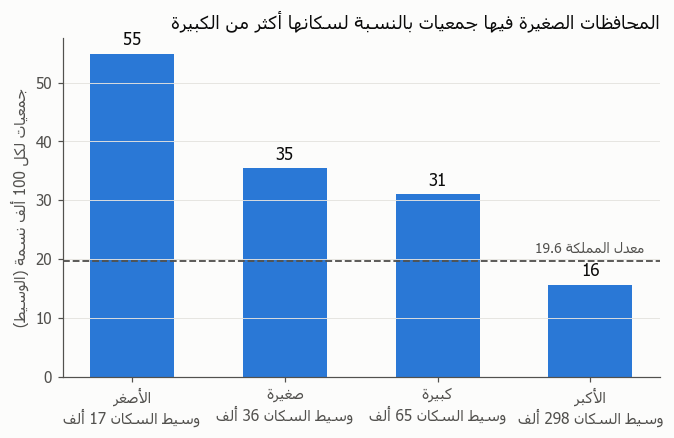

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
labels = [ar(name) + '\n' + ar(f'وسيط السكان {pop / 1000:,.0f} ألف') for name, pop in zip(by_size.index, by_size['population_median'])]
bars = ax.bar(labels, by_size['per_100k_median'], color=BLUE, width=0.55)
ax.bar_label(bars, fmt='%.0f', padding=3, color=INK, fontsize=11)
ax.axhline(NATIONAL_RATE, color=INK_2, linestyle='--', linewidth=1.2)
ax.text(3.35, NATIONAL_RATE + 1.5, ar(f'معدل المملكة {NATIONAL_RATE:.1f}'), color=INK_2, ha='right', fontsize=9)
ax.set_ylabel(ar('جمعيات لكل 100 ألف نسمة (الوسيط)'))
ax.set_title(ar('المحافظات الصغيرة فيها جمعيات بالنسبة لسكانها أكثر من الكبيرة'), color=INK, fontsize=12, loc='right')
ax.grid(axis='x', visible=False)
fig.savefig(FIGURES / 'fig1_rate_by_size.png')
plt.show()

**النتيجة:** المعدل ليس ثابتًا؛ المحافظات الأصغر فيها جمعيات لكل 100 ألف نسمة أكثر بكثير من الأكبر.
السبب المنطقي: كل محافظة تحتاج جمعيات أساسية (بر، تحفيظ، تنمية أهلية) مهما صغر حجمها، بينما الجمعية في المدينة الكبيرة تخدم عددًا أكبر من الناس.

لو استخدمنا النسبة الثابتة، ستظهر المدن الكبيرة كلها "ناقصة" والصغيرة كلها "مكتملة"، وهذا ناتج عن طريقة الحساب وليس عن احتياج حقيقي. لذلك نحتاج طريقة تقارن كل محافظة بالمحافظات التي في حجمها.

### 2. نموذج تعلّم الآلة: خط يمثّل "الطبيعي" لكل حجم

**نوع النموذج:** تعلّم آلة **مُوجَّه (Supervised Learning)** من نوع **الانحدار الخطي (Linear Regression)**، باستخدام `LinearRegression` من مكتبة **scikit-learn**.

| | |
|---|---|
| **المدخل (Feature)** | لوغاريتم عدد سكان المحافظة |
| **الهدف (Target)** | لوغاريتم عدد الجمعيات في المحافظة |
| **بيانات التدريب** | 150 محافظة (تعداد 2022) |
| **التحقق** | تحقق متقاطع بخمس طيّات (5-Fold Cross-Validation) |
| **المخرج** | العدد المتوقع لكل محافظة + نطاق طبيعي (فاصل تنبؤ 80%) |

**الفكرة ببساطة:** نرسم كل محافظة كنقطة (السكان مقابل عدد الجمعيات)، ويتعلّم النموذج **أفضل خط يمر بين النقاط**.
الخط يجيب: كم جمعية تكون عادةً في محافظة بهذا الحجم؟ والمحافظة التي تقع تحت الخط بكثير هي المرشحة للأولوية.

**لماذا تعلّم الآلة هنا؟** لأن النسبة الثابتة (الخطوة 1) متحيزة ضد المدن الكبيرة؛ النموذج **يتعلم العلاقة الفعلية من البيانات** بدل افتراضها، فيقارن كل محافظة بمثيلاتها في الحجم.

**لماذا الانحدار الخطي وليس نموذجًا أعقد** (مثل Random Forest)؟ لدينا 150 محافظة ومتغير رئيسي واحد؛ النموذج الأعقد لا يضيف دقة هنا ويزيد خطر "حفظ" البيانات، بينما الانحدار الخطي **قابل للتفسير**: يمكن شرح نتيجته للمانحين برقم واحد (الميل).

نستخدم **المقياس اللوغاريتمي** للمحورين لأن السكان يتراوحون من 7 آلاف إلى 7 ملايين؛ في هذا المقياس كل خطوة على المحور تعني "عشرة أضعاف"، فتظهر المحافظات الصغيرة والكبيرة بوضوح على رسم واحد.

**كيف نتأكد أن النموذج جيد؟**
- **الميل:** لو كانت النسبة الثابتة عادلة لكان الميل = 1. أي رقم أقل من 1 يعني أن الجمعيات تزيد أبطأ من السكان.
- **R²:** نسبة الاختلاف بين المحافظات التي يفسرها عدد السكان (من 0 إلى 1).
- **التحقق المتقاطع:** ندرّب النموذج على 80% من المحافظات ونختبره على 20% لم يرها، ونكرر ذلك 5 مرات؛ إذا بقيت الدقة قريبة من دقة التدريب فالنموذج لا "يحفظ" البيانات بل يتعلم العلاقة فعلًا.

In [22]:
X = np.log(gov[['population']])
y = np.log(gov['npo_count'])
n = len(gov)

model = LinearRegression().fit(X, y)
log_pred = model.predict(X)
slope = model.coef_[0]

# 95% confidence interval for the slope
residual_sd = np.sqrt(((y - log_pred) ** 2).sum() / (n - 2))
x = X['population']
sxx = ((x - x.mean()) ** 2).sum()
slope_se = residual_sd / np.sqrt(sxx)
t95 = stats.t.ppf(0.975, n - 2)
print(f'Slope: {slope:.2f}  (95% CI {slope - t95 * slope_se:.2f} to {slope + t95 * slope_se:.2f}; 1.0 = fixed rate)')
print(f'Meaning: when population doubles, nonprofits grow by about {(2 ** slope - 1) * 100:.0f}%, not 100%')

print(f'\nR² (all governorates): {model.score(X, y):.2f}')
cv_r2 = cross_val_score(LinearRegression(), X, y, cv=KFold(5, shuffle=True, random_state=42), scoring='r2')
print(f'R² (5-fold cross-validation, unseen governorates): {cv_r2.mean():.2f} ± {cv_r2.std():.2f}')

# Sensitivity check: Riyadh city hosts the headquarters of most national organizations
no_riyadh = gov['governorate'] != 'الرياض'
slope_no_riyadh = LinearRegression().fit(X[no_riyadh], y[no_riyadh]).coef_[0]
print(f'\nSlope without Riyadh city: {slope_no_riyadh:.2f} (Riyadh city does not drive the result)')

Slope: 0.70  (95% CI 0.62 to 0.78; 1.0 = fixed rate)
Meaning: when population doubles, nonprofits grow by about 63%, not 100%

R² (all governorates): 0.66
R² (5-fold cross-validation, unseen governorates): 0.60 ± 0.10

Slope without Riyadh city: 0.69 (Riyadh city does not drive the result)


### 3. المتوقع لكل محافظة، والنطاق الطبيعي

- **المتوقع** = قيمة الخط عند حجم المحافظة.
- **النطاق الطبيعي** = المدى الذي تقع فيه 80% من المحافظات التي في نفس الحجم (فاصل التنبؤ 80%).
  الفرق الصغير عن المتوقع قد يكون صدفة؛ لذلك لا نعتبر المحافظة "أقل من المتوقع" إلا إذا كانت **تحت هذا النطاق**.

اخترنا 80% لأن الهدف **فرز أولي** يوجّه المانحين لدراسة الاحتياج، وليس حكمًا نهائيًا؛ ونعرض أيضًا المحافظات تحت نطاق 95% كأعلى درجات الأولوية.

In [23]:
se_pred = residual_sd * np.sqrt(1 + 1 / n + (x - x.mean()) ** 2 / sxx)
t80 = stats.t.ppf(0.90, n - 2)

gov['expected'] = np.exp(log_pred)
gov['expected_low'] = np.exp(log_pred - t80 * se_pred)
gov['expected_high'] = np.exp(log_pred + t80 * se_pred)
gov['gap'] = gov['npo_count'] - gov['expected']
gov['actual_vs_expected'] = gov['npo_count'] / gov['expected']

gov['status'] = 'ضمن الطبيعي'
gov.loc[gov['npo_count'] < gov['expected_low'], 'status'] = 'أقل من المتوقع بوضوح'
gov.loc[gov['npo_count'] > gov['expected_high'], 'status'] = 'أعلى من المتوقع بوضوح'
gov['below_95'] = gov['npo_count'] < np.exp(log_pred - t95 * se_pred)

display(gov['status'].value_counts().to_frame('governorates'))
print('\nBelow the 95% range (highest priority):', gov['below_95'].sum())

,governorates
status,
ضمن الطبيعي,125
أقل من المتوقع بوضوح,14
أعلى من المتوقع بوضوح,11



Below the 95% range (highest priority): 4


### 4. مقارنة الطريقتين

نطبّق الطريقتين على نفس المحافظات: النسبة الثابتة (المتوقع = السكان × معدل المملكة) والنموذج.

In [24]:
gov['expected_fixed'] = gov['population'] * NATIONAL_RATE / 100_000

examples = gov[gov['governorate'].isin(['جدة', 'تيماء'])].set_index('governorate')
display(examples[['population', 'npo_count', 'expected_fixed', 'expected', 'status']].round(0))

flagged_by_size = pd.DataFrame({
    'fixed_rate: below national rate': (gov['npo_count'] < gov['expected_fixed']).groupby(gov['size_group'], observed=True).sum(),
    'model: clearly below expected': (gov['status'] == 'أقل من المتوقع بوضوح').groupby(gov['size_group'], observed=True).sum(),
})
print('\nGovernorates flagged, by size group:')
flagged_by_size

,population,npo_count,expected_fixed,expected,status
governorate,,,,,
جدة,3751722,415,735.0,334.0,ضمن الطبيعي
تيماء,42165,5,8.0,14.0,أقل من المتوقع بوضوح



Governorates flagged, by size group:


,fixed_rate: below national rate,model: clearly below expected
size_group,,
الأصغر,5,4
صغيرة,5,3
كبيرة,9,3
الأكبر,24,4


**النتيجة:** النسبة الثابتة تصنّف معظم المحافظات الكبيرة كـ"ناقصة" ولا تكاد تصنّف أي محافظة صغيرة، بينما النموذج يوزّع المحافظات المحتاجة على كل الأحجام لأنه يقارن كل محافظة بمثيلاتها.
مثال: **جدة** تبدو ناقصة بالنسبة الثابتة، لكنها فوق المتوقع لحجمها؛ و**تيماء** تبدو قريبة من المعدل، لكنها أقل بكثير من المحافظات التي في حجمها.

### 5. قائمة الأولويات للمانحين

المحافظات التي عدد جمعياتها **تحت النطاق الطبيعي** لحجمها، مرتبة من الأشد نقصًا (أقل نسبة من المتوقع).
المحافظات المستحدثة عليها ملاحظة: قد تكون بعض جمعياتها ما زالت مسجلة تحت المحافظة الأم، فتحتاج تحققًا قبل القرار.

In [25]:
priority = gov[gov['status'] == 'أقل من المتوقع بوضوح'].sort_values('actual_vs_expected').copy()
priority['priority'] = np.where(priority['below_95'], 'عالية جدًا', 'عالية')
priority['note'] = np.where(priority['split_from'].notna(),
                            'محافظة مستحدثة: قد تكون بعض جمعياتها مسجلة في المحافظة الأم', '')
priority = priority[['region', 'governorate', 'population', 'npo_count', 'expected', 'expected_low',
                     'gap', 'actual_vs_expected', 'priority', 'note']].reset_index(drop=True)
priority.index += 1
priority.round({'expected': 1, 'expected_low': 1, 'gap': 1, 'actual_vs_expected': 2})

,region,governorate,population,npo_count,expected,expected_low,gap,actual_vs_expected,priority,note
1,المنطقة الشرقية,النعيرية,63815,2,19.1,8.2,-17.1,0.10,عالية جدًا,
2,المنطقة الشرقية,رأس تنورة,62314,3,18.8,8.0,-15.8,0.16,عالية جدًا,
3,جازان,الحرث,11561,1,5.8,2.4,-4.8,0.17,عالية جدًا,
4,المنطقة الشرقية,العديد,8635,1,4.7,2.0,-3.7,0.21,عالية جدًا,محافظة مستحدثة: قد تكون بعض جمعياتها مسجلة في المحافظة الأم
5,الجوف,طبرجل,109796,8,28.0,11.9,-20.0,0.29,عالية,محافظة مستحدثة: قد تكون بعض جمعياتها مسجلة في المحافظة الأم
6,المنطقة الشرقية,الجبيل,505162,24,81.7,34.6,-57.7,0.29,عالية,
7,المنطقة الشرقية,بقيق,64632,6,19.3,8.2,-13.3,0.31,عالية,
8,جازان,الطوال,36259,4,12.9,5.5,-8.9,0.31,عالية,محافظة مستحدثة: قد تكون بعض جمعياتها مسجلة في المحافظة الأم
9,نجران,ثار,13391,2,6.4,2.7,-4.4,0.31,عالية,
10,جازان,هروب,30709,4,11.4,4.9,-7.4,0.35,عالية,محافظة مستحدثة: قد تكون بعض جمعياتها مسجلة في المحافظة الأم


In [26]:
print('Priority governorates per region:')
display(priority['region'].value_counts().to_frame('governorates'))

priority.round(2).to_csv(OUTPUTS / 'priority_governorates.csv', index_label='rank', encoding='utf-8-sig')
(gov.drop(columns=['size_group'])
    .round({'per_100k': 1, 'expected': 1, 'expected_low': 1, 'expected_high': 1, 'gap': 1,
            'actual_vs_expected': 2, 'expected_fixed': 1})
    .to_csv(OUTPUTS / 'governorate_gap_analysis.csv', index=False, encoding='utf-8-sig'))
print('\nSaved:', OUTPUTS / 'priority_governorates.csv', '|', OUTPUTS / 'governorate_gap_analysis.csv')

Priority governorates per region:


,governorates
region,
المنطقة الشرقية,5
جازان,3
نجران,2
تبوك,2
الجوف,1
الرياض,1



Saved: outputs\priority_governorates.csv | outputs\governorate_gap_analysis.csv


### 6. الرسوم

**الرسم 2:** كل نقطة محافظة. الخط الأزرق هو المتوقع، والشريط حوله هو النطاق الطبيعي (80%).
النقاط البرتقالية تحت الشريط هي المحافظات الأقل من المتوقع بوضوح.

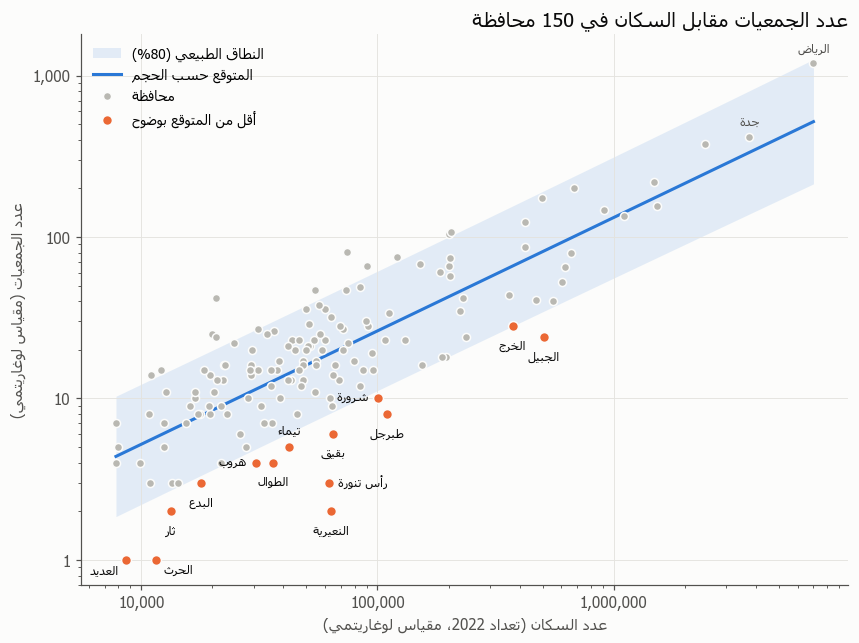

In [27]:
order = np.argsort(gov['population'].values)
pop_sorted = gov['population'].values[order]
below = gov['status'] == 'أقل من المتوقع بوضوح'

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.fill_between(pop_sorted, gov['expected_low'].values[order], gov['expected_high'].values[order],
                color=BLUE, alpha=0.12, linewidth=0, label=ar('النطاق الطبيعي (80%)'))
ax.plot(pop_sorted, gov['expected'].values[order], color=BLUE, linewidth=2, label=ar('المتوقع حسب الحجم'))
ax.scatter(gov.loc[~below, 'population'], gov.loc[~below, 'npo_count'], s=28, color=GRAY,
           edgecolor=SURFACE, linewidth=1, label=ar('محافظة'), zorder=3)
ax.scatter(gov.loc[below, 'population'], gov.loc[below, 'npo_count'], s=42, color=ORANGE,
           edgecolor=SURFACE, linewidth=1, label=ar('أقل من المتوقع بوضوح'), zorder=4)

# Label positions (dx, dy, ha, va) for points that sit close together; the rest go below their point
LABEL_OFFSETS = {
    'العديد': (-5, -3, 'right', 'top'), 'الحرث': (5, -3, 'left', 'top'),
    'هروب': (-6, 0, 'right', 'center'), 'تيماء': (0, 7, 'center', 'bottom'),
    'رأس تنورة': (6, 0, 'left', 'center'), 'شرورة': (-6, 0, 'right', 'center'),
}
for _, row in gov[below].iterrows():
    dx, dy, ha, va = LABEL_OFFSETS.get(row['governorate'], (0, -9, 'center', 'top'))
    ax.annotate(ar(row['governorate']), (row['population'], row['npo_count']), xytext=(dx, dy),
                textcoords='offset points', ha=ha, va=va, fontsize=8, color=INK)
for name in ['جدة', 'الرياض', 'تيماء']:
    row = gov.loc[gov['governorate'] == name].iloc[0]
    if row['status'] != 'أقل من المتوقع بوضوح':
        ax.annotate(ar(name), (row['population'], row['npo_count']), xytext=(0, 7),
                    textcoords='offset points', ha='center', fontsize=8, color=INK_2)

ax.set_xscale('log')
ax.set_yscale('log')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_xlabel(ar('عدد السكان (تعداد 2022، مقياس لوغاريتمي)'))
ax.set_ylabel(ar('عدد الجمعيات (مقياس لوغاريتمي)'))
ax.set_title(ar('عدد الجمعيات مقابل السكان في 150 محافظة'), color=INK, fontsize=13, loc='right')
ax.legend(loc='upper left', frameon=False, fontsize=9)
fig.savefig(FIGURES / 'fig2_population_vs_npo.png')
plt.show()

**الرسم 3:** لكل محافظة في قائمة الأولويات: **كم نسبة جمعياتها الموجودة من العدد المتوقع لحجمها.**
الخط المتقطع عند 100% يمثّل المتوقع؛ كلما قصر الشريط كانت الفجوة أكبر. مثال: النعيرية 10% تعني أن فيها جمعيتين فقط من 19 متوقعة لمحافظة بحجمها.

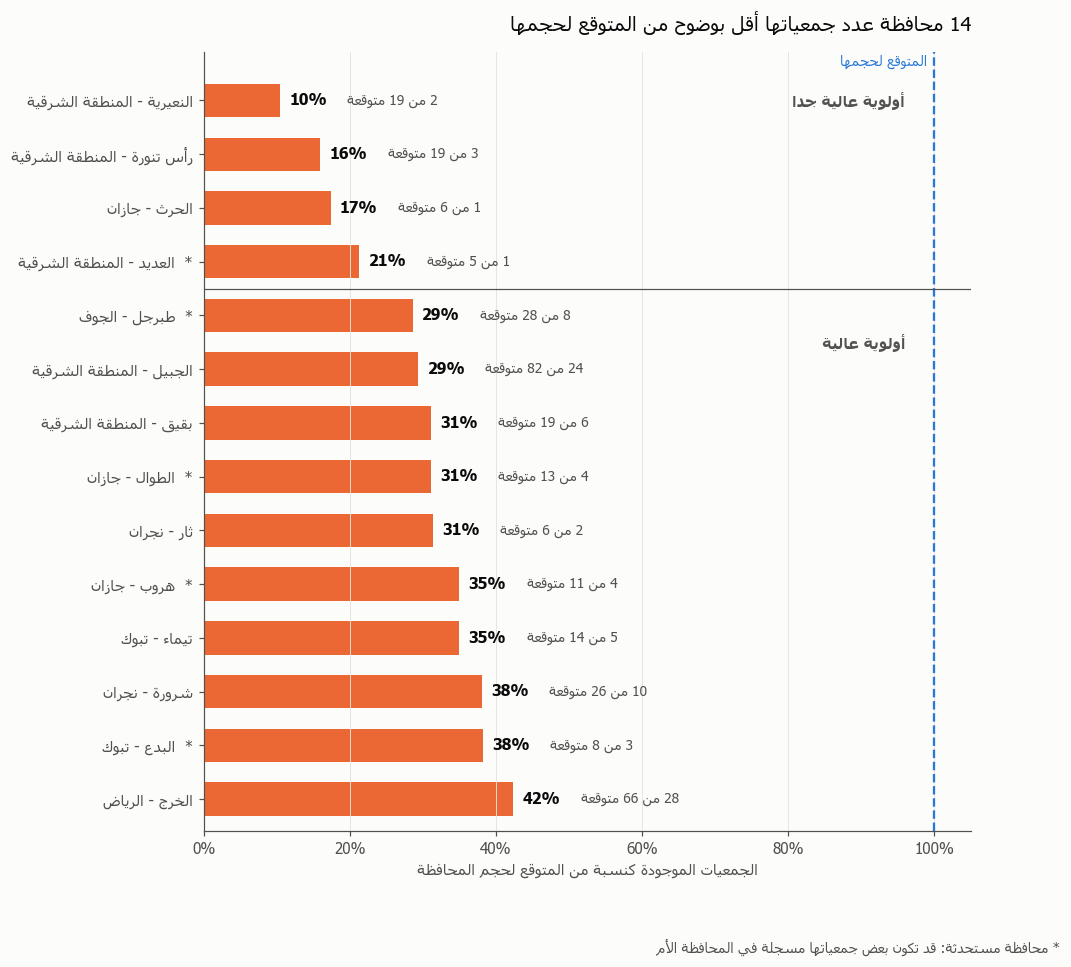

In [28]:
plot = priority.sort_values('actual_vs_expected', ascending=False).reset_index(drop=True)
pct = plot['actual_vs_expected'] * 100
ypos = np.arange(len(plot))
labels = [ar(f"{g} - {r}") + ('  *' if note else '') for g, r, note in zip(plot['governorate'], plot['region'], plot['note'])]

fig, ax = plt.subplots(figsize=(9, 0.5 * len(plot) + 2.2))
ax.barh(ypos, pct, color=ORANGE, height=0.62)
for yp, p, actual, expected in zip(ypos, pct, plot['npo_count'], plot['expected']):
    ax.annotate(f'{p:.0f}%', (p, yp), xytext=(6, 0), textcoords='offset points',
                va='center', fontsize=10, color=INK, fontweight='bold')
    ax.annotate(ar(f'{actual} من {expected:.0f} متوقعة'), (p, yp), xytext=(44, 0), textcoords='offset points',
                va='center', fontsize=9, color=INK_2)

ax.axvline(100, color=BLUE, linestyle='--', linewidth=1.5)
ax.annotate(ar('المتوقع لحجمها'), (100, len(plot) - 0.4), xytext=(-5, 0), textcoords='offset points',
            ha='right', va='bottom', fontsize=9, color=BLUE)

# Separate the highest-priority group (below the 95% range) from the rest
n_very_high = (plot['priority'] == 'عالية جدًا').sum()
split = len(plot) - n_very_high - 0.5
ax.axhline(split, color=INK_2, linewidth=0.8)
ax.text(96, len(plot) - 1, ar('أولوية عالية جدًا'), ha='right', va='center', fontsize=10, color=INK_2, fontweight='bold')
ax.text(96, split - 1, ar('أولوية عالية'), ha='right', va='center', fontsize=10, color=INK_2, fontweight='bold')

ax.set_yticks(ypos, labels, fontsize=10)
ax.set_xlim(0, 105)
ax.set_ylim(-0.6, len(plot) - 0.1)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_xlabel(ar('الجمعيات الموجودة كنسبة من المتوقع لحجم المحافظة'))
ax.grid(axis='y', visible=False)
ax.set_title(ar(f'{len(plot)} محافظة عدد جمعياتها أقل بوضوح من المتوقع لحجمها'), color=INK, fontsize=13, loc='right', pad=14)
fig.text(0.99, -0.01, ar('* محافظة مستحدثة: قد تكون بعض جمعياتها مسجلة في المحافظة الأم'),
         ha='right', fontsize=9, color=INK_2)
fig.savefig(FIGURES / 'fig3_priority_governorates.png')
plt.show()